# L13b Advanced: The SPY Model at the One-Minute Timescale
Previously, we fit a jump hidden Markov model to the daily growth rate of `SPY` and tested it on later days. Does the same model work when the time step is one minute instead of one day?

This material is optional and is not needed for the lecture or its examples.

> __Learning Objectives:__
>
> By the end of this notebook, you should be able to:
> * __Fit the model to one-minute growth rates:__ Build the hidden Markov model from the minutes of 2025, with a time step of one minute. Tune jump episodes to the volatility clustering of the minutes, and compare both versions with the real minutes.
> * __Test the model one trading day at a time:__ Score each trading day of 2025 and 2026 against simulated days of the same length. Relate the score of a day to its volatility.
> * __Refit the model on the recent past:__ Refit the model before each trading day of 2026 on the days just before it. Compare its scores with those of the model fitted to 2025.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

__JumpHMM.jl:__ The [JumpHMM.jl package](https://varnerlab.github.io/JumpHMM.jl/dev/) implements the jump hidden Markov model. The `Include.jl` file imports it with `import JumpHMM`, so we call its functions with the package name in front, for example `JumpHMM.build(...)`. This keeps them apart from functions with the same names in other packages.

### Data
We load the one-minute bars of `SPY` from the `data/SPY-OHLCV-1-min-2025-2026.jld2` file with [the `load(...)` function from JLD2.jl](https://juliaio.github.io/JLD2.jl/stable/basic_usage/#FileIO-interface). Each bar holds the open, high, low, and close prices of one minute, its volume, and its volume-weighted average price.

The bars cover the regular trading session, from 9:30 to 16:00 New York time, between January 2, 2025 and November 13, 2026. On the three days with an early close, the session ends at 13:00. We downloaded the bars from the Alpaca market data service.

We keep the bars in the `bars::DataFrame` variable, one row per minute:

In [2]:
bars = let

    # initialize: the file with the one-minute bars of SPY -
    path = joinpath(_PATH_TO_DATA, "SPY-OHLCV-1-min-2025-2026.jld2");

    # load the bars: one row per minute of the regular session, in New York time -
    bars = load(path, "dataset"); # columns: timestamp, open, high, low, close, volume, vwap

    # checks: positive prices, in time order -
    @assert all(bars.close .> 0) "closing prices must be positive"
    @assert issorted(bars.timestamp) "the time stamps should run forward in time"

    # return -
    bars
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values:

In [3]:
Δt = 1 / (252 * 390); # one minute, expressed in years: a trading year has 252 days of 390 minutes
number_of_states = 100; # number of hidden states N, the bins of the growth rate
ν = 5.0; # degrees of freedom of the Student-t distribution in each state
number_of_paths = 1000; # number of simulated paths, or simulated days, that we compare with the data
random_seed = 5660; # fix the random numbers, so every run gives the same paths
start_time_to_visualize = DateTime(2025, 4, 9, 13, 0); # first minute of the candlestick chart in Task 1, New York time, on a trading day
number_of_minutes_to_visualize = 60; # number of one-minute bars in the candlestick chart, at least 1; the chart must end by the close of that day
day_to_visualize = "volatile"; # the day of 2026 plotted in Task 2: "calm" (lowest volatility ratio), "typical" (closest to one), or "volatile" (highest)
α = 0.05; # significance level of the test; a path passes when its p-value is above α
number_of_lags = 780; # lags (minutes) of the autocorrelation check; 780 minutes are two full trading days
window_days = 21; # number of trading days before each test day that we refit the model on in Task 3, at least 1
ϵ_range = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3]; # candidate probabilities (per minute) that a jump episode starts, tuned in Task 1
λ_range = [30.0, 60.0, 120.0, 390.0, 780.0, 1950.0]; # candidate mean episode lengths (minutes), from half an hour to five trading days
number_of_tuning_paths = 20; # number of simulated years of minutes used to score each (ϵ, λ) pair, at least 1

Next, we compute the growth rate of minute $t$ from the closing prices of two consecutive minutes. We use only consecutive minutes of the same day. We leave out the first minute of each day, because its change from the previous close includes the overnight move. A full trading day gives 389 growth rates.

We fit the model to the minutes of 2025 and test it on the minutes of 2026. [The `Date(...)` function](https://docs.julialang.org/en/v1/stdlib/Dates/#Dates.Date-Tuple{DateTime}) gives the trading day of each bar.

We keep the trading days in the `days::Array{Date,1}` variable, and the growth rates of each day in the `growth_rates::Array{Array{Float64,1},1}` variable, one array per day. The `fit_index::Array{Int64,1}` and `test_index::Array{Int64,1}` variables hold the positions of the days of 2025 and 2026 in `days`. The `g_fit::Array{Float64,1}` variable holds the growth rates of 2025, one day after the other:

In [4]:
days, growth_rates, fit_index, test_index, g_fit = let

    # initialize: the trading day of each bar, and the trading days in time order -
    day_of_bar = Date.(bars.timestamp); # the trading day of each one-minute bar
    days = unique(day_of_bar); # the trading days, in time order
    growth_rates = Array{Array{Float64,1},1}(); # one array of growth rates per trading day (1/yr)

    # the growth rates of each day, from the closing prices of consecutive minutes of that day -
    for d ∈ days
        prices = bars.close[day_of_bar .== d]; # closing prices of the minutes of day d (USD/share)
        g = Array{Float64,1}(); # growth rates of day d (1/yr)
        for t ∈ 2:length(prices) # start at the second minute: the first minute follows the previous close
            push!(g, (1 / Δt) * log(prices[t] / prices[t - 1]));
        end
        push!(growth_rates, g);
    end

    # split: the days of 2025 are the fitting period, the days of 2026 the test period -
    fit_index = findall(year.(days) .== 2025); # positions of the days of 2025 in days
    test_index = findall(year.(days) .== 2026); # positions of the days of 2026 in days
    g_fit = Array{Float64,1}(); # the growth rates of 2025, one day after the other (1/yr)
    for i ∈ fit_index
        append!(g_fit, growth_rates[i]);
    end

    # checks: one array per day, finite growth rates, and the test days after the fitting days -
    @assert length(growth_rates) == length(days) "there should be one array of growth rates per trading day"
    @assert all(isfinite, g_fit) "growth rates must be finite"
    @assert last(fit_index) < first(test_index) "the test days should come after the fitting days"

    # return -
    (days, growth_rates, fit_index, test_index, g_fit)
end;

___

## Task 1: Fit the Model to the Minutes of 2025
In this task, we fit the hidden Markov model to the one-minute growth rates of 2025 and compare simulated minutes with the real ones over the whole year. [The `JumpHMM.build(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.build-Tuple{Type{MyJumpHiddenMarkovModel},%20NamedTuple}) fits the same parts as in the daily model: the state bins, the transition matrix, and a Student-t emission for each state. Only the time step changes.

First, let's look at the one-minute bars of `SPY` as a candlestick chart. `Unhide` the code block below to see how we drew `number_of_minutes_to_visualize` bars, starting at `start_time_to_visualize`, with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot). The body of each candle runs from the open price to the close price of the minute, and the whiskers reach its high and low prices.

What does the market look like one minute at a time?

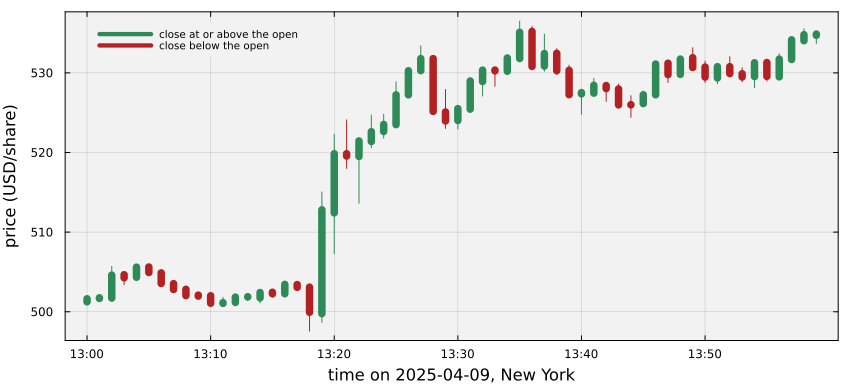

In [5]:
let

    # initialize: the bars of the chart, from start_time_to_visualize to the close of that day at the latest -
    on_that_day = Date.(bars.timestamp) .== Date(start_time_to_visualize); # true for the bars of the day of the start time
    from_start = bars.timestamp .>= start_time_to_visualize; # true for the bars at or after the start time
    available = findall(on_that_day .& from_start); # positions of the bars that the chart can show
    number_of_bars = min(number_of_minutes_to_visualize, length(available)); # the chart stops at the close
    window = bars[available[1:number_of_bars], :]; # one row per minute of the chart

    # the candles: a whisker from the low to the high, and a body from the open to the close.
    # A NaN ends a line, so one series can draw many separate candles -
    rise_x = Float64[]; # position of each minute that closed at or above its open, twice, then NaN
    rise_body = Float64[]; # open and close of those minutes (USD/share)
    rise_whisker = Float64[]; # low and high of those minutes (USD/share)
    fall_x = Float64[]; # position of each minute that closed below its open, twice, then NaN
    fall_body = Float64[]; # open and close of those minutes (USD/share)
    fall_whisker = Float64[]; # low and high of those minutes (USD/share)
    for k ∈ 1:number_of_bars
        if window.close[k] >= window.open[k]
            append!(rise_x, [k, k, NaN]);
            append!(rise_body, [window.open[k], window.close[k], NaN]);
            append!(rise_whisker, [window.low[k], window.high[k], NaN]);
        else
            append!(fall_x, [k, k, NaN]);
            append!(fall_body, [window.open[k], window.close[k], NaN]);
            append!(fall_whisker, [window.low[k], window.high[k], NaN]);
        end
    end

    # plot: the whiskers as thin lines, then the bodies as thick lines on top -
    # display options used in this cell -
    # lw: Set the line width in points; the bodies get thinner when we show more minutes.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    body_width = max(1.0, min(8.0, 450 / number_of_minutes_to_visualize)); # body width in points
    p = plot(rise_x, rise_whisker, lw = 1, c = :seagreen, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm)
    plot!(fall_x, fall_whisker, lw = 1, c = :firebrick, label = "")
    plot!(rise_x, rise_body, lw = body_width, c = :seagreen, label = "close at or above the open")
    plot!(fall_x, fall_body, lw = body_width, c = :firebrick, label = "close below the open")

    # the horizontal axis: about six time labels, in New York time -
    step_size = max(1, div(number_of_bars, 6)); # minutes between two labels
    if step_size >= 5
        step_size = 5 * div(step_size, 5); # a whole number of 5-minute steps
    end
    positions = collect(1:step_size:number_of_bars); # positions of the labels
    labels = Dates.format.(window.timestamp[positions], "HH:MM"); # hour and minute of each label
    xticks!(positions, labels)
    xlabel!("time on $(Date(start_time_to_visualize)), New York"); ylabel!("price (USD/share)")

    # checks: the chart has at least one minute, starts during the session of a trading day, and ends by its close -
    @assert number_of_minutes_to_visualize >= 1 "number_of_minutes_to_visualize must be at least 1"
    @assert number_of_bars >= 1 "start_time_to_visualize must fall during the session of a trading day in the data"
    @assert number_of_bars == number_of_minutes_to_visualize "the chart runs past the close; choose fewer minutes or an earlier start time"

    # return -
    p
end

We fit two versions of the model: one without jump episodes, and one with episodes tuned to the volatility clustering of the minutes. For the first version, we set the episode probability $\epsilon$ to zero. We keep the model without jumps in the `model::JumpHMM.MyJumpHiddenMarkovModel` variable:

In [6]:
model = let

    # fit the state bins, transition matrix, and Student-t emissions to the minutes of 2025 -
    model = JumpHMM.build(JumpHMM.MyJumpHiddenMarkovModel, (
        growth_rates = g_fit, # one-minute growth rates of SPY in 2025 (1/yr)
        number_of_states = number_of_states, # number of growth-rate bins, one for each hidden state
        ν = ν, # Student-t degrees of freedom within each state; smaller values give heavier tails
        Δt = Δt # time between closing prices: one minute, in years
    ));

    # no jumps: set the episode probability ϵ = 0, so no episode can start -
    model.ϵ = 0.0; # ϵ = 0 per minute

    # checks: the number of states and no jumps -
    @assert model.number_of_states == number_of_states "the model should have number_of_states states"
    @assert model.ϵ == 0.0 "the model should have no jump episodes"

    # return -
    model
end;

__Tuning the jump episodes:__ In the daily model, jump episodes restored part of the volatility clustering. [The `JumpHMM.tune(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.tune-Tuple{MyJumpHiddenMarkovModel,%20Vector{Float64}}) tries each episode probability $\epsilon$ (per minute) in `ϵ_range` with each mean episode length $\lambda$ (minutes) in `λ_range`. It scores each pair by how well the simulated paths match the autocorrelation of $|g_{t}|$ and the excess kurtosis of the data.

At the one-minute scale, a few extreme minutes give the data a very large excess kurtosis. With the default weight, the kurtosis error decides the score. The tuning then picks episodes too rare and too short to change the clustering.

We set the weight of the kurtosis error, the `w_κ` argument, to zero and tune the episodes on the clustering alone. We keep the model with tuned episodes in the `tuned_model::JumpHMM.MyJumpHiddenMarkovModel` variable:

In [7]:
tuned_model = let

    # tune: keep the (ϵ, λ) pair whose simulated paths best match the clustering of the real minutes -
    tuned_model = JumpHMM.tune(model, g_fit;
        ϵ_range = ϵ_range, # candidate probabilities that an episode starts in a given minute
        λ_range = λ_range, # candidate mean episode lengths, in minutes
        number_of_paths = number_of_tuning_paths, # simulated years of minutes used to score each candidate pair
        w_κ = 0.0, # weight of the kurtosis error in the score; zero scores the clustering alone
        seed = random_seed # reproduce the random draws used during tuning
    );

    # checks: the tuned model has jump episodes, and the model without jumps is unchanged -
    @assert tuned_model.ϵ > 0.0 "the tuned model should have jump episodes"
    @assert model.ϵ == 0.0 "tuning should not change the model without jumps"

    # return -
    tuned_model
end;

Next, we simulate `number_of_paths` paths from each model, each as long as the minutes of 2025, with [the `JumpHMM.simulate(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.simulate-Tuple{MyJumpHiddenMarkovModel,%20Int64}). Each path starts from the stationary distribution, steps the chain with the transition matrix, and draws each minute's growth rate from the Student-t emission of the minute's state.

For each path, we compute the standard deviation and the excess kurtosis of its growth rates with the [`std(...)`](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.std) and [`kurtosis(...)`](https://juliastats.org/StatsBase.jl/stable/scalarstats/#StatsBase.kurtosis) functions. We compare each path with the real minutes by the two-sample Kolmogorov–Smirnov (KS) test. We run the test with [the `ApproximateTwoSampleKSTest(...)` function](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ApproximateTwoSampleKSTest) and read its p-value with [the `pvalue(...)` function](https://juliastats.org/HypothesisTests.jl/stable/methods/#StatsAPI.pvalue).

We save the paths of the model without jumps in the `paths_fit::Array{Float64,2}` variable, one column per path. We save the KS p-value, the standard deviation, and the excess kurtosis of each path in the `ks_fit::Array{Float64,1}`, `std_fit::Array{Float64,1}`, and `kurtosis_fit::Array{Float64,1}` variables:

In [8]:
paths_fit, ks_fit, std_fit, kurtosis_fit = let

    # simulate: number_of_paths paths, each as long as the minutes of 2025 -
    number_of_minutes = length(g_fit); # number of growth rates in 2025
    result = JumpHMM.simulate(model, number_of_minutes;
        number_of_paths = number_of_paths, # number of synthetic years of minutes
        seed = random_seed # reproduce the sampled states and growth rates
    );
    paths_fit = result.growth_rates; # minutes × paths (1/yr)

    # score: compare each path with the real minutes of 2025 -
    ks_fit = Array{Float64,1}(undef, number_of_paths); # KS p-value of each path
    std_fit = Array{Float64,1}(undef, number_of_paths); # standard deviation of each path (1/yr)
    kurtosis_fit = Array{Float64,1}(undef, number_of_paths); # excess kurtosis of each path
    for j ∈ 1:number_of_paths
        path = paths_fit[:, j]; # growth rates of path j (1/yr)
        ks_fit[j] = pvalue(ApproximateTwoSampleKSTest(g_fit, path));
        std_fit[j] = std(path);
        kurtosis_fit[j] = StatsBase.kurtosis(path);
    end

    # checks: one column per path, and p-values between zero and one -
    @assert size(paths_fit) == (number_of_minutes, number_of_paths) "unexpected size of the simulated paths"
    @assert all(0.0 .<= ks_fit .<= 1.0) "KS p-values must be between zero and one"

    # return -
    (paths_fit, ks_fit, std_fit, kurtosis_fit)
end;

We do the same for the model with tuned episodes, and also count the simulated minutes that fall in an episode. We save the results in the `paths_episode::Array{Float64,2}`, `ks_episode::Array{Float64,1}`, `std_episode::Array{Float64,1}`, and `kurtosis_episode::Array{Float64,1}` variables, and the share of the simulated minutes in an episode in the `episode_share::Float64` variable:

In [9]:
paths_episode, ks_episode, std_episode, kurtosis_episode, episode_share = let

    # simulate: number_of_paths paths of the tuned model, each as long as the minutes of 2025 -
    number_of_minutes = length(g_fit); # number of growth rates in 2025
    result = JumpHMM.simulate(tuned_model, number_of_minutes;
        number_of_paths = number_of_paths, # number of synthetic years of minutes
        seed = random_seed # reproduce the sampled states, growth rates, and jump episodes
    );
    paths_episode = result.growth_rates; # minutes × paths (1/yr)
    episode_share = count(result.episodes) / length(result.episodes); # episodes is true on the episode minutes

    # score: compare each path with the real minutes of 2025 -
    ks_episode = Array{Float64,1}(undef, number_of_paths); # KS p-value of each path
    std_episode = Array{Float64,1}(undef, number_of_paths); # standard deviation of each path (1/yr)
    kurtosis_episode = Array{Float64,1}(undef, number_of_paths); # excess kurtosis of each path
    for j ∈ 1:number_of_paths
        path = paths_episode[:, j]; # growth rates of path j (1/yr)
        ks_episode[j] = pvalue(ApproximateTwoSampleKSTest(g_fit, path));
        std_episode[j] = std(path);
        kurtosis_episode[j] = StatsBase.kurtosis(path);
    end

    # checks: one column per path, p-values between zero and one, and a share between zero and one -
    @assert size(paths_episode) == (number_of_minutes, number_of_paths) "unexpected size of the simulated paths"
    @assert all(0.0 .<= ks_episode .<= 1.0) "KS p-values must be between zero and one"
    @assert 0.0 <= episode_share <= 1.0 "the share of episode minutes must be between zero and one"

    # return -
    (paths_episode, ks_episode, std_episode, kurtosis_episode, episode_share)
end;

The table, made with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table), shows the standard deviation and the excess kurtosis of the real minutes of 2025, next to their means over the simulated paths of each model. The last row gives the tuned values of $\epsilon$ (per minute) and $\lambda$ (minutes).

The table also shows the share of paths with a KS p-value above the significance level $\alpha$, and the share of the simulated minutes in a jump episode:

In [10]:
let

    # count the paths of each model that pass the KS test -
    passed_fit = 0; # paths of the model without jumps with a KS p-value above α
    passed_episode = 0; # paths of the tuned model with a KS p-value above α
    for j ∈ 1:number_of_paths
        if ks_fit[j] > α
            passed_fit += 1;
        end
        if ks_episode[j] > α
            passed_episode += 1;
        end
    end

    # one row for the real minutes, one for each model -
    episode_label = "simulated, ϵ = $(tuned_model.ϵ), λ = $(round(Int, tuned_model.λ))"; # the tuned episode probability (per minute) and mean length (minutes)
    df = DataFrame(group = String[], std = Float64[], kurt = Float64[], ks = Any[], share = Any[]); # Any holds a number or a dash
    push!(df, ("real SPY, 2025", std(g_fit), StatsBase.kurtosis(g_fit), "—", "—"));
    push!(df, ("simulated, no jumps", mean(std_fit), mean(kurtosis_fit), passed_fit / number_of_paths, 0.0));
    push!(df, (episode_label, mean(std_episode), mean(kurtosis_episode), passed_episode / number_of_paths, episode_share));

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["", "standard deviation (1/yr)", "excess kurtosis", "pass rate, KS", "episode minutes (share)"], # displayed column headings, including units
        alignment = [:l, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3, 4, 5])], # print the numbers in these columns to three decimal places; the dashes print as they are
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 --------------------------------- --------------------------- ----------------- --------------- -------------------------
                                    standard deviation (1/yr)   excess kurtosis   pass rate, KS   episode minutes (share) 
 --------------------------------- --------------------------- ----------------- --------------- -------------------------
  real SPY, 2025                                       45.714           177.327               —                         —
  simulated, no jumps                                  48.304            42.828           0.000                     0.000
  simulated, ϵ = 0.0003, λ = 1950                      82.864            14.295           0.000                     0.367
 --------------------------------- --------------------------- ----------------- --------------- -------------------------


__Why does every path fail the test?__ With almost 97,000 minutes in each sample, the KS test finds even small differences between two distributions. To judge the model by large differences only, we score one trading day at a time in Task 2.

The real minutes hold a few extreme moves from early April 2025, when tariff news moved the market. These few minutes give the real minutes a larger excess kurtosis than the simulated paths of either model.

`Unhide` the code block below to see how we plotted the distribution of the growth rate on each simulated path of both models, next to the real minutes. [The `growth_rate_density(...)` function](docs/growth-rate-density.md), from the `src/Helper.jl` file, estimates each density from a histogram with narrow bins.

> __What do we see?__ The paths without jumps match the spread of the real minutes. The paths with tuned episodes are wider, with a hump on each side of zero.
>
> The humps are the episode minutes: during an episode, each minute jumps to one of the tail states, the states of the largest falls and rises. The episodes cover a large share of the minutes, which raises the standard deviation and lowers the excess kurtosis.

Do the simulated minutes look like the minutes of `SPY`?

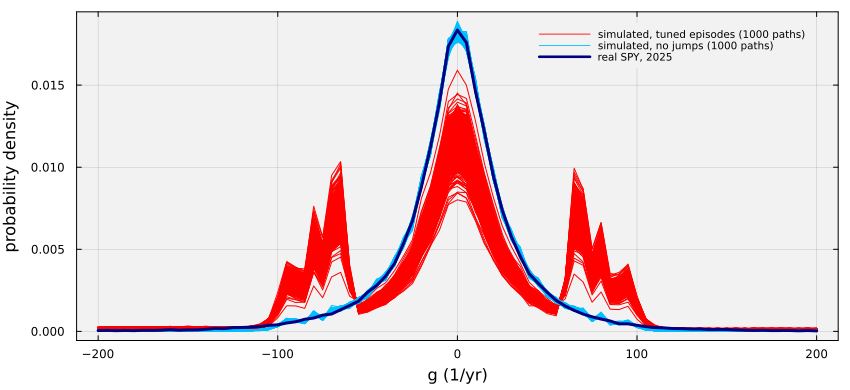

In [11]:
let

    # initialize: the bins of the growth rate, and the density of the real minutes -
    edges = -202.5:5.0:202.5; # bin edges (1/yr), with one bin centered on zero; the few minutes outside this range are not plotted
    centers = (edges[1:end-1] .+ edges[2:end]) ./ 2; # the middle of each bin (1/yr)
    density_real = growth_rate_density(g_fit, edges); # density of the real minutes of 2025

    # plot: the density of the growth rate on each simulated path, tuned episodes first -
    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm)
    for j ∈ 1:number_of_paths
        label = ""; # one legend entry for the paths with tuned episodes
        if j == 1
            label = "simulated, tuned episodes ($(number_of_paths) paths)";
        end
        plot!(centers, growth_rate_density(paths_episode[:, j], edges), lw = 1, c = :red, label = label)
    end
    for j ∈ 1:number_of_paths
        label = ""; # one legend entry for the paths without jumps
        if j == 1
            label = "simulated, no jumps ($(number_of_paths) paths)";
        end
        plot!(centers, growth_rate_density(paths_fit[:, j], edges), lw = 1, c = :deepskyblue1, label = label)
    end

    # plot: the real minutes on top -
    plot!(centers, density_real, lw = 3, c = :navy, label = "real SPY, 2025")
    xlabel!("g (1/yr)"); ylabel!("probability density")
end

Next, we check whether the growth rate of one minute predicts the growth rate of the next. `Unhide` the code block below to see how we plotted the autocorrelation of $g_{t}$ for the real minutes and for the simulated paths without jumps, with [the `StatsBase.autocor(...)` function](https://juliastats.org/StatsBase.jl/stable/signalcorr/#StatsBase.autocor).

The dashed lines mark the 95% band for white noise, $\pm 1.96/\sqrt{T}$, where $T$ is the number of minutes in 2025.

> __What do we see?__ The autocorrelation of $g_{t}$ for the real minutes stays between −0.03 and 0.03. With almost 97,000 minutes, the band is narrow, and many lags fall just outside it. The growth rate of one minute tells us almost nothing about the growth rate of the next.
>
> The mean over the simulated paths stays inside the band.

Does the growth rate of one minute predict the next one?

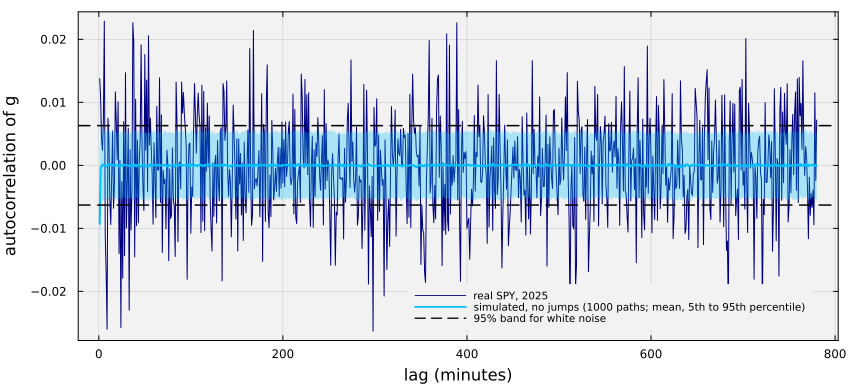

In [12]:
let

    # initialize: the lags, the 95% band, and the autocorrelation of g for the real minutes -
    lags = 1:number_of_lags; # minutes
    band = 1.96 / sqrt(length(g_fit)); # 95% band for the autocorrelation of white noise, T = number of minutes in 2025
    acf_real = StatsBase.autocor(g_fit, lags);

    # the autocorrelation of g on each simulated path without jumps -
    acf_sim = Array{Float64,2}(undef, number_of_lags, number_of_paths); # lags × paths
    for j ∈ 1:number_of_paths
        acf_sim[:, j] = StatsBase.autocor(paths_fit[:, j], lags); # autocorrelation of path j
    end

    # the mean and the middle 90% of the simulated paths at each lag -
    m = Array{Float64,1}(undef, number_of_lags); # mean over the paths
    lo = Array{Float64,1}(undef, number_of_lags); # 5th percentile over the paths
    hi = Array{Float64,1}(undef, number_of_lags); # 95th percentile over the paths
    for k ∈ lags
        m[k] = mean(acf_sim[k, :]);
        lo[k] = quantile(acf_sim[k, :], 0.05);
        hi[k] = quantile(acf_sim[k, :], 0.95);
    end

    # plot: the real minutes as a line; at this many lags, sticks would merge into a solid block -
    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # ribbon: Give the distances below and above the mean for the shaded interval.
    # fillalpha: Set the shaded interval opacity between zero and one.
    # ls: Choose the line style; :dash draws a dashed reference line.
    plot(lags, acf_real, lw = 1, c = :navy, label = "real SPY, 2025",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm)

    # plot: the mean and the middle 90% of the simulated paths, and the band -
    plot!(lags, m, ribbon = (m .- lo, hi .- m), lw = 2, c = :deepskyblue1, fillalpha = 0.3,
        label = "simulated, no jumps ($(number_of_paths) paths; mean, 5th to 95th percentile)")
    hline!([band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!("lag (minutes)"); ylabel!("autocorrelation of g")
end

Next, we check volatility clustering at the one-minute scale. `Unhide` the code block below to see how we plotted the autocorrelation of $|g_{t}|$ for the real minutes and for the simulated paths of both models, with the same 95% band.

> __What do we see?__
>
> * __Real minutes:__ The autocorrelation of $|g_{t}|$ starts near 0.4 and stays near 0.2 for two trading days, far above the band. The bump near 390 minutes, one trading day, comes from the daily pattern of volatility: the minutes after the open and before the close move more than the minutes at midday.
> * __No jumps:__ The simulated paths forget a volatile minute within a few minutes, as the daily model without jumps forgot a volatile day within a few days.
> * __Tuned episodes:__ The mean autocorrelation follows the real minutes for about one trading day and then falls below them. The episodes restore most of the clustering, but they change the distribution of the growth rate.
>
> Neither model knows the time of day, and neither shows the bump near 390 minutes.

How long does volatility cluster at the one-minute scale?

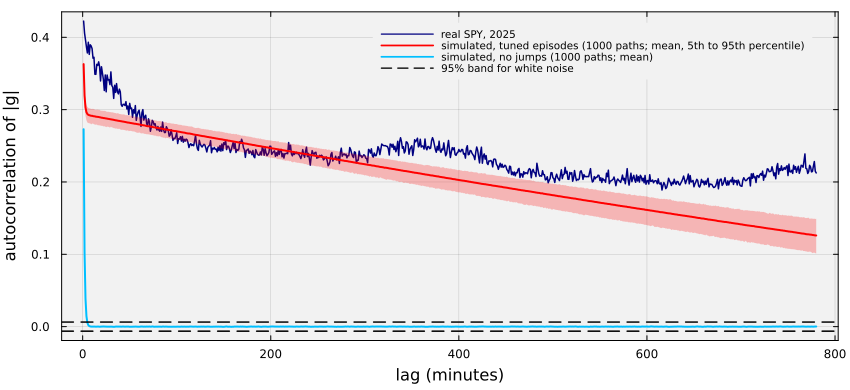

In [13]:
let

    # initialize: the lags, the 95% band, and the autocorrelation of |g| for the real minutes -
    lags = 1:number_of_lags; # minutes
    band = 1.96 / sqrt(length(g_fit)); # 95% band for the autocorrelation of white noise, T = number of minutes in 2025
    acf_real = StatsBase.autocor(abs.(g_fit), lags);

    # the autocorrelation of |g| on each simulated path of both models -
    acf_fit = Array{Float64,2}(undef, number_of_lags, number_of_paths); # lags × paths, no jumps
    acf_episode = Array{Float64,2}(undef, number_of_lags, number_of_paths); # lags × paths, tuned episodes
    for j ∈ 1:number_of_paths
        acf_fit[:, j] = StatsBase.autocor(abs.(paths_fit[:, j]), lags); # autocorrelation of path j, no jumps
        acf_episode[:, j] = StatsBase.autocor(abs.(paths_episode[:, j]), lags); # autocorrelation of path j, tuned episodes
    end

    # the mean over the paths at each lag, and the middle 90% of the paths with tuned episodes -
    m_fit = Array{Float64,1}(undef, number_of_lags); # mean over the paths without jumps
    m_episode = Array{Float64,1}(undef, number_of_lags); # mean over the paths with tuned episodes
    lo_episode = Array{Float64,1}(undef, number_of_lags); # 5th percentile over the paths with tuned episodes
    hi_episode = Array{Float64,1}(undef, number_of_lags); # 95th percentile over the paths with tuned episodes
    for k ∈ lags
        m_fit[k] = mean(acf_fit[k, :]);
        m_episode[k] = mean(acf_episode[k, :]);
        lo_episode[k] = quantile(acf_episode[k, :], 0.05);
        hi_episode[k] = quantile(acf_episode[k, :], 0.95);
    end

    # plot: the real minutes as a line; at this many lags, sticks would merge into a solid block -
    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # ribbon: Give the distances below and above the mean for the shaded interval.
    # fillalpha: Set the shaded interval opacity between zero and one.
    # ls: Choose the line style; :dash draws a dashed reference line.
    plot(lags, acf_real, lw = 1.5, c = :navy, label = "real SPY, 2025",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm)

    # plot: the tuned episodes as a mean and its middle 90%, the model without jumps as a mean, and the band -
    plot!(lags, m_episode, ribbon = (m_episode .- lo_episode, hi_episode .- m_episode), lw = 2, c = :red, fillalpha = 0.25,
        label = "simulated, tuned episodes ($(number_of_paths) paths; mean, 5th to 95th percentile)")
    plot!(lags, m_fit, lw = 2, c = :deepskyblue1, label = "simulated, no jumps ($(number_of_paths) paths; mean)")
    hline!([band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!("lag (minutes)"); ylabel!("autocorrelation of |g|")
end

___

## Task 2: Test the Model One Trading Day at a Time
In this task, we score the model without jumps on each trading day of 2025 and 2026, against simulated days of the same length. [The `pass_rate(...)` function](docs/pass-rate.md), from the `src/Helper.jl` file, simulates `number_of_paths` days and returns the share of simulated days that pass the KS test against the real day.

We measure the volatility of a day by the standard deviation of its growth rates. The volatility ratio of a day divides its volatility by the [median](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.median) volatility of the days of 2025. A day with a volatility ratio of one is as volatile as a typical day of 2025.

We save the pass rate of each day in the `daily_pass::Array{Float64,1}` variable, and its volatility ratio in the `volatility_ratio::Array{Float64,1}` variable, in the order of `days`:

In [14]:
daily_pass, volatility_ratio = let

    # initialize: one entry per trading day, 2025 and 2026 -
    number_of_days = length(days); # number of trading days
    daily_pass = Array{Float64,1}(undef, number_of_days); # pass rate of each day
    volatility = Array{Float64,1}(undef, number_of_days); # standard deviation of the growth rates of each day (1/yr)

    # score each day against number_of_paths simulated days of the same length -
    for i ∈ 1:number_of_days
        daily_pass[i] = pass_rate(model, growth_rates[i];
            number_of_paths = number_of_paths, # number of simulated days
            α = α, # a simulated day passes when its p-value is above α
            seed = random_seed + i # a new seed for each day, the same in every run
        );
        volatility[i] = std(growth_rates[i]);
    end

    # the volatility ratio: the volatility of each day, divided by that of a typical day of 2025 -
    typical_volatility = median(volatility[fit_index]); # median over the days of 2025 (1/yr)
    volatility_ratio = volatility ./ typical_volatility; # 1 means as volatile as a typical day of 2025

    # checks: one entry per day, pass rates between zero and one -
    @assert length(daily_pass) == length(days) "there should be one pass rate per trading day"
    @assert all(0.0 .<= daily_pass .<= 1.0) "pass rates must be between zero and one"

    # return -
    (daily_pass, volatility_ratio)
end;

The table shows, for each year, the number of trading days, the [mean](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.mean) pass rate over the days, and the share of days on which more than half of the simulated days pass:

In [15]:
let

    # initialize: the two groups of days -
    labels = ["2025, the fitting period", "2026, the test period"];
    groups = [fit_index, test_index];

    # one row per group: the mean pass rate, and the share of days on which more than half of the simulated days pass -
    df = DataFrame(group = String[], days = Int64[], mean_pass = Float64[], share = Float64[]);
    for k ∈ eachindex(labels)
        n = length(groups[k]); # number of days in this group
        number_above_half = 0; # days with a pass rate above one half
        for i ∈ groups[k]
            if daily_pass[i] > 0.5
                number_above_half += 1;
            end
        end
        push!(df, (labels[k], n, mean(daily_pass[groups[k]]), number_above_half / n));
    end

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["", "trading days", "mean pass rate", "share of days with a pass rate above 0.5"], # displayed column headings
        alignment = [:l, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4])], # print the numbers in these columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 -------------------------- -------------- ---------------- ------------------------------------------
                             trading days   mean pass rate   share of days with a pass rate above 0.5 
 -------------------------- -------------- ---------------- ------------------------------------------
  2025, the fitting period            250            0.352                                      0.348
  2026, the test period               219            0.426                                      0.452
 -------------------------- -------------- ---------------- ------------------------------------------


The model passes more often on the days of 2026 than on the days of 2025, the year it was fitted to. A model fitted to a whole year describes a typical day of that year. The days of 2025 include the turmoil of April and many calm days in the summer.

`Unhide` the code block below to see how we plotted the distribution of the growth rate on one trading day of 2026, next to the simulated days that the `pass_rate(...)` function compared with it. The `day_to_visualize` constant chooses the day. We draw each density with [the `density(...)` function](https://docs.juliaplots.org/stable/api/#Plots.density-Tuple).

> __What do we see?__ On a typical day, the real distribution lies among the simulated days, and most simulated days pass. On a calm day, the real distribution is narrower than the simulated days. On a volatile day, the real distribution is wider than the simulated days.
>
> The simulated days all have about the volatility of a typical day of 2025. Change `day_to_visualize` to see each case.

Which days does the model of 2025 describe?

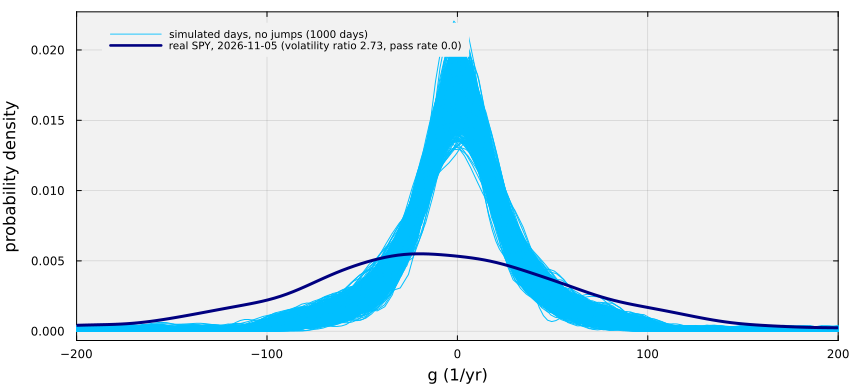

In [16]:
let

    # initialize: the day of 2026 chosen by day_to_visualize -
    ratios = volatility_ratio[test_index]; # volatility ratio of each day of 2026
    k = 1; # position of the chosen day in test_index; the first day of 2026 until a case below matches
    if day_to_visualize == "calm"
        k = argmin(ratios); # the calmest day of 2026
    elseif day_to_visualize == "typical"
        k = argmin(abs.(ratios .- 1.0)); # the day of 2026 closest to a typical day of 2025
    elseif day_to_visualize == "volatile"
        k = argmax(ratios); # the most volatile day of 2026
    end

    # the real day, and the simulated days that pass_rate(...) compared with it: same model, length, and seed -
    i = test_index[k]; # position of the day in days
    real_day = growth_rates[i]; # growth rates of the day (1/yr)
    result = JumpHMM.simulate(model, length(real_day);
        number_of_paths = number_of_paths, # number of simulated days
        seed = random_seed + i # the seed of this day in Task 2
    );
    simulated_days = result.growth_rates; # minutes × simulated days (1/yr)

    # plot: the density of each simulated day, then the real day on top -
    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color or, for a heatmap, the color palette.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # size: Set the complete figure width and height in pixels.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # legend: Place the legend; :topleft keeps it clear of the peaks.
    p = density(simulated_days[:, 1], lw = 1, c = :deepskyblue1, label = "simulated days, no jumps ($(number_of_paths) days)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7,
        size = (850, 390), left_margin = 3Plots.mm, bottom_margin = 4Plots.mm, legend = :topleft)
    for j ∈ 2:number_of_paths
        density!(simulated_days[:, j], lw = 1, c = :deepskyblue1, label = "")
    end
    ratio_text = round(volatility_ratio[i], digits = 2); # volatility ratio of the day, for the legend
    pass_text = round(daily_pass[i], digits = 2); # pass rate of the day, for the legend
    density!(real_day, lw = 3, c = :navy, label = "real SPY, $(days[i]) (volatility ratio $(ratio_text), pass rate $(pass_text))")
    xlims!(-200, 200)
    xlabel!("g (1/yr)"); ylabel!("probability density")

    # checks: day_to_visualize names one of the three cases -
    @assert in(day_to_visualize, ["calm", "typical", "volatile"]) "day_to_visualize must be calm, typical, or volatile"

    # return -
    p
end

___

## Task 3: Refit the Model on the Recent Past
In this task, we refit the model before each trading day of 2026 on the `window_days` trading days just before it, and compare its scores with those of the model fitted to 2025. The refit model has the same number of states, Student-t degrees of freedom, and time step as the model of 2025, and no jump episodes.

Early in January, the window reaches back into December 2025. We score each test day with the `pass_rate(...)` function and the same seed as in Task 2.

We save the pass rates in the `refit_pass::Array{Float64,1}` variable, in the order of `test_index`:

In [ ]:
refit_pass = let

    # initialize: one entry per test day -
    number_of_test_days = length(test_index); # number of trading days in 2026
    refit_pass = Array{Float64,1}(undef, number_of_test_days); # pass rate of each test day

    # refit the model on the window_days trading days before each test day, and score the day -
    for k ∈ 1:number_of_test_days
        i = test_index[k]; # position of the test day in days

        # the growth rates of the window, one day after the other (1/yr) -
        window = Array{Float64,1}();
        for j ∈ (i - window_days):(i - 1)
            append!(window, growth_rates[j]);
        end

        # refit: the same settings as the model of 2025, on the window -
        refit_model = JumpHMM.build(JumpHMM.MyJumpHiddenMarkovModel, (
            growth_rates = window, # one-minute growth rates of the window (1/yr)
            number_of_states = number_of_states, # number of growth-rate bins, one for each hidden state
            ν = ν, # Student-t degrees of freedom within each state
            Δt = Δt # one minute, in years
        ));
        refit_model.ϵ = 0.0; # no jump episodes, as in the model of 2025

        # score the test day with the same seed as in Task 2 -
        refit_pass[k] = pass_rate(refit_model, growth_rates[i];
            number_of_paths = number_of_paths, # number of simulated days
            α = α, # a simulated day passes when its p-value is above α
            seed = random_seed + i # the seed of this day in Task 2
        );
    end

    # checks: the windows start inside the data, and pass rates between zero and one -
    @assert first(test_index) - window_days >= 1 "window_days reaches back before the first day of the data"
    @assert all(0.0 .<= refit_pass .<= 1.0) "pass rates must be between zero and one"

    # return -
    refit_pass
end;

The table compares the two models on the trading days of 2026, with the same columns as in Task 2:

In [ ]:
let

    # initialize: the pass rates of the test days under each model -
    labels = ["fitted to 2025", "refit on the $(window_days) trading days before each day"];
    pass_rates = [daily_pass[test_index], refit_pass];

    # one row per model: the mean pass rate, and the share of days on which more than half of the simulated days pass -
    df = DataFrame(model = String[], days = Int64[], mean_pass = Float64[], share = Float64[]);
    for k ∈ eachindex(labels)
        n = length(pass_rates[k]); # number of test days
        number_above_half = 0; # days with a pass rate above one half
        for rate ∈ pass_rates[k]
            if rate > 0.5
                number_above_half += 1;
            end
        end
        push!(df, (labels[k], n, mean(pass_rates[k]), number_above_half / n));
    end

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["model", "trading days", "mean pass rate", "share of days with a pass rate above 0.5"], # displayed column headings
        alignment = [:l, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4])], # print the numbers in these columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

Refitting on the recent past raises the mean pass rate and the share of days that pass. The refit model follows the volatility of the market, with a delay of about `window_days` trading days. Your results may differ if you change `window_days`.

___

## Summary
In this notebook, we fit the hidden Markov model of `SPY` to one-minute growth rates instead of daily ones. We fit the model with and without jump episodes and compared the simulated minutes with the real ones over the whole year. We then scored the model one trading day at a time and refit it on the recent past.

> __Key Takeaways:__
>
> * __Jump episodes trade fat tails for clustering:__ We fit the hidden Markov model to the minutes of 2025, with and without jump episodes. Without jumps, the simulated minutes matched the spread of the real minutes but forgot a volatile minute within a few minutes. The tuned episodes restored most of the clustering, but they widened the distribution and lowered the excess kurtosis.
> * __The score of a day follows its volatility:__ We scored each trading day of 2025 and 2026 against simulated days of the same length. The model passed on days about as volatile as a typical day of 2025, and failed on calm and on volatile days.
> * __Refitting follows the volatility of the market:__ We refit the model before each trading day of 2026 on the trading days just before it. The refit model passed on more days than the model fitted to 2025, because its simulated days follow the volatility of the market with a delay of about `window_days` trading days.

At the one-minute scale, a model of `SPY` has to follow the volatility of the market from day to day.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___